# Potencia frente a PD subestimadas y las probabilidades de rechazo exactas que no necesitan simulación

**Pregunta:** ¿Cuánto debe estar subestimada una PD para que las pruebas de calibración la detecten con una potencia de 80 %, y qué pruebas necesitan el mayor error para lograrlo?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 02 de este tema (la tasa y su error de Monte Carlo, el tamaño de cada prueba)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- plantar una PD subestimada de tamaño conocido con el generador del estudio y ver cómo luce un conjunto ante una prueba de calibración;
- calcular la potencia exacta de una prueba de conteo con `rejection_probability`, sin simulación, y decir por qué el motor puede hacerlo;
- contrastar la potencia simulada con esa curva exacta, punto a punto, en toda la escalera del estudio;
- hallar, con un buscador de raíces, la severidad con que una prueba llega a 80 % de potencia y comparar las pruebas con ella;
- explicar por qué la prueba del perfil de incumplimientos es ciega a una PD demasiado baja por el mismo factor en cada grado, y qué cuesta en potencia la corrección de Vasicek.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import optimize

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son la familia `miscalibration` del caso C22, validar al validador. En cada conjunto las PD que recibe la prueba son $1/k$ de las PD verdaderas, de modo que el modelo subestima el riesgo en el factor $k$, que recorre una escalera de 1 (sin defecto) a 3. Los conjuntos los sortean generadores de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`); la verdad de cada uno dice cuántos incumplimientos esperar y si la nula se cumple.

- **Archivo que se lee:** `data/derived/C22/miscalibration.json`, claves `outputs` (las simulaciones, los generadores y la escalera), `impact` y `provenance`.
- **Qué se toma de él:** la configuración del generador, la semilla y las repeticiones de cada peldaño. El motor vuelve a sortear los conjuntos aquí y mide la potencia.

La celda siguiente carga el archivo, indexa las filas e imprime la escalera con las versiones del motor.

In [2]:
# Cargar la familia de descalibración e indexar sus simulaciones por clave
LANG = "es"
ROOT = Path("../../..").resolve()
miscal = json.loads((ROOT / "data" / "derived" / "C22" / "miscalibration.json").read_text(encoding="utf-8"))
out = miscal["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
print("escalera del factor k:", ladder, "|", "simulaciones:", len(rows))
print("calculado con riskvalidation", miscal["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)

escalera del factor k: [1.0, 1.1, 1.25, 1.5, 2.0, 3.0] | simulaciones: 54
calculado con riskvalidation 1.0.1 | instalado 1.0.1


## Método

La potencia de una prueba frente a un defecto es su probabilidad de rechazo cuando el defecto está presente, aquí al nivel de 5 %. Para una prueba que ve la cartera solo a través de su conteo de incumplimientos $D$, la región de rechazo es $D \ge k^*$ y la potencia es una cola binomial,

$$\text{potencia}(k) = P\bigl(D \ge k^*\bigr), \qquad D \sim \mathrm{Binomial}(n,\ k\,\pi_{\text{aplicada}}),$$

de modo que el motor puede calcularla de forma exacta hallando $k^*$ con la prueba registrada. Para las pruebas que miran grados, deudores o años no hay forma cerrada, y la potencia es una tasa de rechazo sobre repeticiones con su intervalo de Wilson (notebook 01). Los pasos plantan el defecto en un conjunto, calculan la potencia exacta de las pruebas de conteo, contrastan la simulación con ella, ubican la severidad de 80 % de potencia y miden después las pruebas que no tienen valor exacto.

### Paso 1: el defecto plantado en un conjunto

El peldaño $k = 1{,}5$ es una cartera de 5.000 deudores con una PD verdadera de 3 % donde el modelo aplica 2 %. El `truth()` del generador dice qué se plantó, y la celda siguiente sortea un conjunto con una semilla fija, lo entrega a las pruebas binomial y de Jeffreys con `feed_cell` e imprime sus valores p y semáforos.

In [3]:
# Sortear un conjunto con el defecto plantado k = 1,5 y correr sobre él las pruebas binomial y de Jeffreys
from riskvalidation.generators.counts import DefaultCounts, feed_cell
from riskvalidation.validation.calibration import pd_binomial, pd_jeffreys

spec = out["generators"]["port-5000-k1.5"]
generator = DefaultCounts(**spec["config"])
truth = generator.truth()
print("PD verdadera:", truth["pd_true"][0][0], "| PD aplicada:", truth["pd_forecast"][0][0])
print("incumplimientos esperados, verdaderos:", truth["expected_defaults"][0][0])
print("la nula se cumple:", truth["calibration_null_holds"])
cell = feed_cell()(generator.draw(np.random.default_rng(5)))
print("deudores:", cell["n"], "| incumplimientos observados:", cell["d"])
for test in (pd_binomial, pd_jeffreys):
    result = test(**cell)
    print(f"{result.test_id:12s} p = {result.p_value:.2e} | semáforo {result.light.value}")

PD verdadera: 0.03 | PD aplicada: 0.02
incumplimientos esperados, verdaderos: 150.0
la nula se cumple: False
deudores: 5000 | incumplimientos observados: 159
pd.binomial  p = 2.31e-08 | semáforo red
pd.jeffreys  p = 1.81e-08 | semáforo red


La cartera debería tener 150 incumplimientos donde la PD aplicada espera 100, y el conjunto sorteado tiene 159. Ambas pruebas quedan en rojo, con valores p de 2,31e-08 para la binomial y 1,81e-08 para la de Jeffreys: con esta severidad y este tamaño el defecto es evidente. La pregunta de la escalera es cuán pequeño puede ser un defecto antes de que un conjunto deje de mostrarlo, y para eso un solo sorteo no sirve, porque un valor p no dice con qué frecuencia la prueba atraparía un factor dado.

### Paso 2: potencia exacta, sin simulación

`critical_count` llama a la prueba registrada con cada conteo hasta que una rechaza, y `rejection_probability` devuelve la cola binomial más allá de él. La celda siguiente calcula la potencia exacta de las pruebas binomial, de Jeffreys y binomial corregida por Vasicek para factores de 1 a 3 en una malla fina, imprime el conteo crítico de cada una y la potencia en $k = 1{,}5$, y dibuja las tres curvas con la línea de 80 %. La prueba corregida supone una correlación de activos de 12 %, así que su conteo crítico es mucho más alto.

pd.binomial          conteo crítico 118 | potencia en k = 1,5 0.9973
pd.jeffreys          conteo crítico 117 | potencia en k = 1,5 0.9980
pd.binomial_vasicek  conteo crítico 287 | potencia en k = 1,5 0.0000


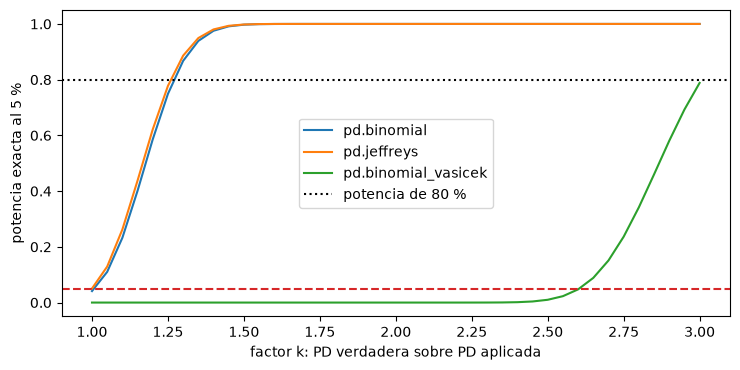

In [4]:
# Potencia exacta de las tres pruebas de conteo en una malla fina del factor k, y conteo crítico de cada una
from riskvalidation.harness.exact import critical_count, rejection_probability

extra = {"pd.binomial": {}, "pd.jeffreys": {}, "pd.binomial_vasicek": {"rho": 0.12}}
ks = np.linspace(1.0, 3.0, 41)
power = {}
for test, kw in extra.items():
    power[test] = [rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k, **kw)["probability"] for k in ks]
    k_star = critical_count(test, 5000, 0.02, 0.05, **kw)
    print(f"{test:20s} conteo crítico {k_star} | potencia en k = 1,5 {power[test][10]:.4f}")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for test in extra:
    ax.plot(ks, power[test], label=test)
ax.axhline(0.8, color="black", linestyle=":", label="potencia de 80 %")
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel("factor k: PD verdadera sobre PD aplicada")
ax.set_ylabel("potencia exacta al 5 %")
ax.legend()
fig.tight_layout()
plt.show()

Las curvas de la binomial y de Jeffreys suben juntas y alcanzan potencia plena antes de $k = 1{,}5$: en ese peldaño sus potencias son 0,9973 y 0,9980, con conteos críticos de 118 y 117 incumplimientos frente a los 100 esperados. La prueba corregida es otra historia. Necesita 287 incumplimientos para rechazar, así que en $k = 1{,}5$ su potencia es 0,0000 y su curva solo sube en el extremo derecho de la escalera. La corrección protege de falsas alarmas bajo correlación, y la figura muestra lo que quita a la potencia bajo independencia.

### Paso 3: ¿concuerda la simulación con la curva exacta?

Cada peldaño de la escalera tiene una semilla y una configuración de generador. La celda siguiente corre las tres pruebas en los seis peldaños con `simulate`, 2.000 repeticiones cada una, calcula la potencia exacta en el mismo peldaño, escribe la mayor brecha estandarizada entre los 18 puntos y dibuja las tasas simuladas con sus intervalos de Wilson sobre las curvas exactas del paso anterior.

puntos simulados: 18 | mayor brecha estandarizada: 2.14


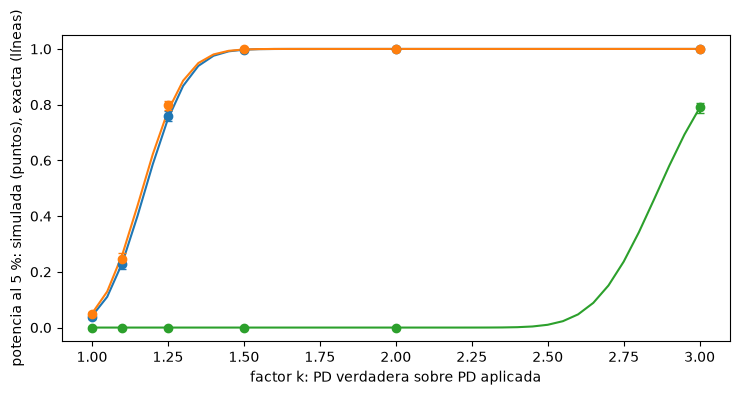

In [5]:
# Simular las tres pruebas en cada peldaño de la escalera y poner cada tasa junto a la curva exacta
from riskvalidation.harness.run import simulate

fig, ax = plt.subplots(figsize=(7.5, 3.8))
largest = 0.0
for index, (test, kw) in enumerate(extra.items()):
    ax.plot(ks, power[test], color=f"C{index}")
    for k in ladder:
        row = rows[f"{test}@k{k:g}"]
        gen = DefaultCounts(**out["generators"][row["generator"]]["config"])
        run = simulate(test, gen, n_rep=row["n_rep"], seed=row["seed"], feed=feed_cell(), test_kwargs=kw)
        measured = run.rates["p<0.05"]
        exact = rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k, **kw)["probability"]
        low, high = measured.interval
        errors = [[measured.rate - low], [high - measured.rate]]
        ax.errorbar(k, measured.rate, yerr=errors, fmt="o", capsize=3, color=f"C{index}")
        if 0 < exact < 1:
            largest = max(largest, abs(measured.rate - exact) / np.sqrt(exact * (1 - exact) / measured.n))
print("puntos simulados:", 3 * len(ladder), "| mayor brecha estandarizada:", round(float(largest), 2))
ax.set_xlabel("factor k: PD verdadera sobre PD aplicada")
ax.set_ylabel("potencia al 5 %: simulada (puntos), exacta (líneas)")
fig.tight_layout()
plt.show()

Los 18 puntos simulados caen sobre sus curvas exactas, y la mayor brecha estandarizada es 2,14, bajo el criterio de 3,29 que usa el estudio. La concordancia importa más allá de las pruebas de conteo: muestra que el generador, el arnés y las pruebas registradas están conectados correctamente, de modo que las tasas de las pruebas sin valor exacto, medidas con la misma maquinaria en el paso 5, merecen la misma confianza. Los intervalos en los extremos son diminutos porque allí la potencia está cerca de 0 o de 1.

### Paso 4: la severidad de 80 % de potencia

La potencia es una función no decreciente de $k$, de modo que el factor con que una prueba llega a 80 % es la raíz de $\text{potencia}(k) - 0{,}8$. La celda siguiente la halla con un buscador de raíces por intervalo (`scipy.optimize.brentq`) sobre la potencia exacta del motor para las tres pruebas de conteo, e imprime la PD verdadera que corresponde a ese factor, junto al valor que el archivo informa para la prueba de Jeffreys.

In [6]:
# Hallar el factor k con que cada prueba de conteo llega a 80 % de potencia
def power_gap(k, test, kw):
    return rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k, **kw)["probability"] - 0.8


k80 = {}
for test, kw in extra.items():
    k80[test] = optimize.brentq(power_gap, 1.0, 4.0, args=(test, kw), xtol=1e-9)
    print(f"{test:20s} k con 80 % de potencia {k80[test]:.4f} | PD verdadera {0.02 * k80[test]:.4f}")
print("cifra del archivo, Jeffreys:", round(miscal["impact"]["jeffreys_k80"]["value"], 4))

pd.binomial          k con 80 % de potencia 1.2690 | PD verdadera 0.0254
pd.jeffreys          k con 80 % de potencia 1.2587 | PD verdadera 0.0252
pd.binomial_vasicek  k con 80 % de potencia 3.0069 | PD verdadera 0.0601
cifra del archivo, Jeffreys: 1.2587


La prueba binomial llega a 80 % de potencia con $k = 1{,}2690$ y la de Jeffreys con $1{,}2587$, de modo que ambas detectan una PD verdadera de cerca de 2,5 % frente a 2 % aplicado, una subestimación de un cuarto, cuatro veces de cada cinco. El valor del archivo para la prueba de Jeffreys, 1,2587, es el que devuelve el buscador de raíces. La prueba corregida necesita $k = 3{,}0069$, una PD verdadera de 6,01 %: para protegerse de una correlación de 12 % renuncia a casi toda su sensibilidad ante una PD baja en un cuarto o incluso en la mitad.

### Paso 5: las pruebas sin valor exacto

Tres paneles reúnen las pruebas que miran los grados de calificación (chi-cuadrado sobre siete grados y la prueba del perfil de incumplimientos), a los deudores (Hosmer-Lemeshow y Spiegelhalter sobre un modelo logístico) y los años (la prueba normal y los semáforos a cinco años). La celda siguiente reconstruye el generador de cada peldaño desde el archivo, elige la alimentación que corresponde a su forma, simula cada prueba y dibuja la potencia a lo largo de la escalera, un panel por familia.

pd.chi2_grades           [0.053, 0.16, 0.661, 0.995, 1.0, 1.0]
pd.default_profile       [0.033, 0.038, 0.037, 0.036, 0.033, 0.024]
pd.hosmer_lemeshow       [0.05, 0.168, 0.649, 0.995, 1.0, 1.0]
pd.spiegelhalter         [0.053, 0.412, 0.946, 1.0, 1.0, 1.0]
pd.normal_multiperiod    [0.077, 0.37, 0.863, 1.0, 1.0, 1.0]
pd.traffic_lights        [0.043, 0.278, 0.806, 1.0, 1.0, 1.0]


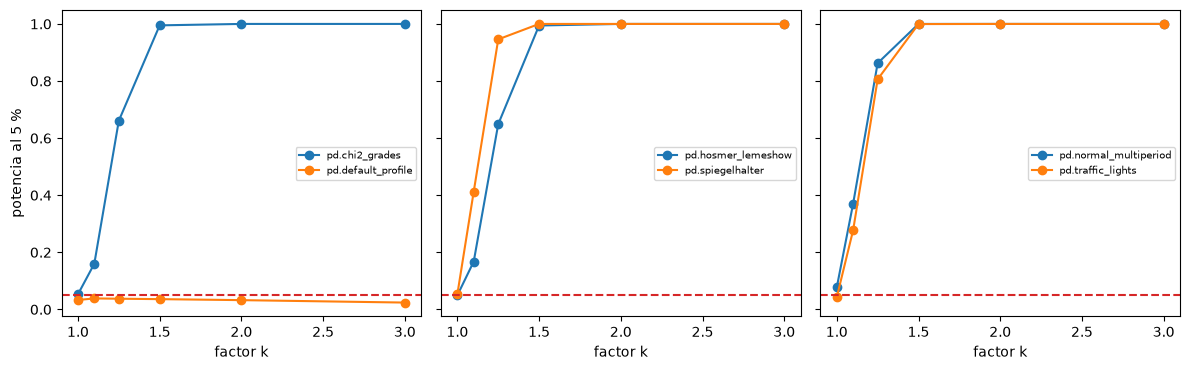

In [7]:
# Simular las pruebas de los paneles de grados, deudores y años a lo largo de la escalera y dibujar los cuatro paneles
from riskvalidation.generators.counts import feed_grades, feed_series
from riskvalidation.generators.scores import LogisticPortfolio

CLASSES = {cls.name: cls for cls in (DefaultCounts, LogisticPortfolio)}
KWARGS = {"pd.default_profile": {"n_sim": 2000}}
panels = {"grades": ("pd.chi2_grades", "pd.default_profile"), "obligors": ("pd.hosmer_lemeshow", "pd.spiegelhalter"),
          "years": ("pd.normal_multiperiod", "pd.traffic_lights")}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (panel, tests) in zip(axes, panels.items()):
    for index, test in enumerate(tests):
        rates = []
        for k in ladder:
            row = rows[f"{test}@k{k:g}"]
            cfg = out["generators"][row["generator"]]
            shape = cfg["config"].get("obligors", [[0]])
            feed = feed_series() if len(shape) > 1 else (feed_grades() if len(shape[0]) > 1 else feed_cell())
            gen = CLASSES[cfg["name"]](**cfg["config"])
            feed = None if cfg["name"] == "logistic_portfolio" else feed
            run = simulate(test, gen, n_rep=row["n_rep"], seed=row["seed"], feed=feed, test_kwargs=KWARGS.get(test))
            rates.append(run.rates["p<0.05"].rate)
        ax.plot(ladder, rates, "o-", label=test)
        print(f"{test:24s}", [round(r, 3) for r in rates])
    ax.axhline(0.05, color="tab:red", linestyle="--")
    ax.set_xlabel("factor k")
    ax.legend(fontsize=7)
axes[0].set_ylabel("potencia al 5 %")
fig.tight_layout()
plt.show()

En el panel de grados, la prueba chi-cuadrado sube de 0,053 en $k = 1$ a 0,995 en $k = 1{,}5$, mientras la prueba del perfil de incumplimientos se mantiene entre 0,024 y 0,038 en toda la escalera. Compara la forma de los incumplimientos sobre los grados, y una PD baja por el mismo factor en cada grado deja intacta la forma. Entre las pruebas sobre deudores, Spiegelhalter es la más sensible, con 0,946 en $k = 1{,}25$ frente a 0,649 de Hosmer-Lemeshow. A cinco años la prueba normal llega a 0,863 en $k = 1{,}25$ y los semáforos a 0,806.

### Paso 6: lo que cuesta la corrección de Vasicek

La corrección existe por una razón (el notebook 04 muestra las falsas alarmas de la prueba sin corregir bajo correlación). Su precio es potencia cuando los incumplimientos son en realidad independientes, como en esta escalera. La celda siguiente calcula la potencia exacta de ambas pruebas en factores más allá de la escalera del archivo, de 2,5 a 4, e imprime los factores de 80 % de las dos.

In [8]:
# Potencia exacta de la prueba corregida de Vasicek más allá de la escalera y su factor k con 80 % de potencia
for k in (2.5, 3.0, 3.5, 4.0):
    plain = rejection_probability("pd.binomial", 5000, 0.02, 0.05, pd_true=0.02 * k)["probability"]
    pd_true = 0.02 * k
    corrected = rejection_probability("pd.binomial_vasicek", 5000, 0.02, 0.05, pd_true=pd_true, rho=0.12)["probability"]
    print(f"k = {k:3.1f} | binomial {plain:.4f} | corregida por correlación {corrected:.4f}")
print("k con 80 % de potencia, corregida:", round(k80["pd.binomial_vasicek"], 4))
print("k con 80 % de potencia, binomial:", round(k80["pd.binomial"], 4))

k = 2.5 | binomial 1.0000 | corregida por correlación 0.0100
k = 3.0 | binomial 1.0000 | corregida por correlación 0.7884
k = 3.5 | binomial 1.0000 | corregida por correlación 0.9999
k = 4.0 | binomial 1.0000 | corregida por correlación 1.0000
k con 80 % de potencia, corregida: 3.0069
k con 80 % de potencia, binomial: 1.269


Más allá de la escalera el contraste es completo. La prueba binomial sin corregir tiene una potencia de 1,0000 desde $k = 2{,}5$, mientras la corregida sube de 0,0100 en $k = 2{,}5$ a 0,7884 en $k = 3{,}0$, 0,9999 en 3,5 y 1,0000 en 4,0. Un validador que aplica la corrección elige una prueba que calla ante una subestimación por un factor de 2,5, un defecto del que la mayoría de los bancos querría enterarse. La elección correcta depende de si los incumplimientos están correlacionados, lo que mide el notebook siguiente.

## Resultados

**Respuesta:** Con 5.000 deudores y una PD aplicada de 2 %, las pruebas binomial y de Jeffreys detectan una PD verdadera de cerca de 2,5 % cuatro veces de cada cinco: llegan a 80 % de potencia con $k = 1{,}2690$ y $k = 1{,}2587$. La prueba binomial corregida necesita $k = 3{,}0069$, una PD verdadera de 6,01 %, y la prueba del perfil de incumplimientos nunca pasa de 0,038 en la escalera, así que no llega a 80 % de potencia con ningún factor probado. Entre las pruebas sin valor exacto, Spiegelhalter alcanza 0,946 de potencia en $k = 1{,}25$ frente a 0,649 de Hosmer-Lemeshow.

- **Un conjunto no es una potencia.** En $k = 1{,}5$ un solo sorteo de 159 incumplimientos da valores p de 2,31e-08, pero la potencia de las mismas pruebas es 0,9973 y 0,9980, una afirmación sobre repeticiones.
- **La potencia exacta y la simulada concuerdan.** La mayor brecha estandarizada entre 18 puntos es 2,14.
- **Una corrección tiene un precio.** En $k = 1{,}5$ la prueba corregida tiene potencia 0,0000 y en $k = 2{,}5$ solo 0,0100, frente a 1,0000 de la no corregida.
- **Una prueba puede ser ciega a un defecto.** La prueba del perfil de incumplimientos lee la forma de los incumplimientos sobre los grados y un factor uniforme no la cambia.

La potencia bajo incumplimientos correlacionados, donde la prueba corregida justifica su existencia, es tarea del notebook 04.

## Resumen

- La potencia es una probabilidad de rechazo frente a un defecto plantado: aquí cada PD verdadera es $k$ veces la PD aplicada, con $k$ de 1 a 3.
- Para las pruebas de conteo la potencia es una cola binomial que el motor calcula llamando a la prueba, y 18 puntos simulados concuerdan con ella.
- Las pruebas binomial y de Jeffreys llegan a 80 % de potencia con una subestimación cercana a un cuarto; la corregida necesita un factor de 3.
- La prueba del perfil de incumplimientos es ciega a un factor uniforme, y las de chi-cuadrado, Hosmer-Lemeshow y Spiegelhalter no lo son.
- Una corrección contra la correlación se paga con potencia cuando los incumplimientos son independientes.

**Qué probar después.** Cambia a 1.000 el número de deudores en la configuración del generador y mira dónde se mueve el factor de 80 %; luego lee el notebook 04.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): el modelo de incumplimiento de un factor, la prueba binomial y su corrección tipo Vasicek, la prueba chi-cuadrado por grados y la prueba de semáforo. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.5.3.1 (la prueba de Jeffreys). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió el artefacto.